# 08 - Evaluation and Error Analysis

In this notebook, we evaluate the final CV-job matching results.

The evaluation focuses on:

- Final match score distribution
- TF-IDF similarity
- Word2Vec similarity
- Skill coverage
- Correlation between matching signals
- Top and lowest matching results
- Difficult matching cases
- Missing skills analysis
- Final evaluation summary

In [28]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 01. Load Final Matching Results

The final dataset generated in the previous step contains the
similarity scores, skill coverage, and final matching percentage.

In [29]:
file_path = Path("../Data/final_matching_results.csv")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)

Dataset shape: (9544, 46)


In [30]:
df.head()

,career_objective,skills,educational_institution_name,degree_names,passing_years,educational_results,result_types,major_field_of_studies,professional_company_names,start_dates,...,word2vec_similarity,skill_coverage_percentage,skill_coverage_score,matched_skills,missing_skills,candidate_record_id,tfidf_scaled,word2vec_scaled,final_match_score,final_match_percentage
0,big data analytics working and database wareho...,"['big data', 'hadoop', 'hive', 'python', 'mapr...",['the amity school of engineering & technology...,['b.tech'],['2019'],['n/a'],[none],['electronics'],['coca-cola'],['nov 2019'],...,0.692982,0.000000,0.000000,[],"['documentation', 'software engineer', 'techni...",1,0.079300,0.672315,0.187904,18.790379
1,fresher looking to join as a data analyst and ...,"['data analysis', 'data analytics', 'business ...","['delhi university - hansraj college', 'delhi ...","['b.sc (maths)', 'm.sc (science) (statistics)']","['2015', '2018']","['n/a', 'n/a']","['n/a', 'n/a']","['mathematics', 'statistics']",['bib consultancy'],['sep 2019'],...,0.834400,37.878788,0.378788,"['data analysis', 'machine learning', 'machine...","['application development', 'functional', 'lea...",2,1.000000,1.000000,0.689394,68.939394
2,NaN,"['software development', 'machine learning', '...","['birla institute of technology (bit), ranchi']",['b.tech'],['2018'],['n/a'],['n/a'],['electronics/telecommunication'],['axis bank limited'],['june 2018'],...,0.473196,0.000000,0.000000,[],"['business administration', 'excel', 'marketin...",3,0.000000,0.000000,0.000000,0.000000
3,to obtain a position in a fast-paced business ...,"['accounts payables', 'accounts receivables', ...","['martinez adult education, business training ...",['computer applications specialist certificate...,['2008'],[none],[none],['computer applications'],"['company name ï¼ city , state', 'company name...","['january 2011', 'january 2008', 'january 2006...",...,0.681219,20.000000,0.200000,['fast'],"['business development', 'quality', 'reliable'...",4,0.270575,0.630209,0.325196,32.519589
4,professional accountant with an outstanding wo...,"['analytical reasoning', 'compliance testing k...",['kent state university'],['bachelor of business administration'],[none],['3.84'],[none],['accounting'],"['company name', 'company name', 'company name...","['january 2016', 'january 2016', 'january 2012...",...,0.549506,0.000000,0.000000,[],"['api', 'application development', 'integratio...",5,0.106971,0.158697,0.066417,6.641692


The final matching results are loaded from the project `Data` folder so the notebook can be reused on another machine.

In [31]:
evaluation_columns=[
    "job_position_name",
    "tfidf_similarity",
    "word2vec_similarity",
    "skill_coverage_score",
    "final_match_percentage"
]

df[evaluation_columns].head(20)

,job_position_name,tfidf_similarity,word2vec_similarity,skill_coverage_score,final_match_percentage
0,senior software engineer,0.003533,0.692982,0.000000,18.790379
1,machine learning (ml) engineer,0.056484,0.834400,0.378788,68.939394
2,"executive/ senior executive- trade marketing, ...",0.000000,0.473196,0.000000,0.000000
3,business development executive,0.012055,0.681219,0.200000,32.519589
4,senior ios engineer,0.004766,0.549506,0.000000,6.641692
5,ai engineer,0.014965,0.717050,0.035714,29.144933
6,senior ios engineer,0.002348,0.506417,0.055556,4.206383
7,senior ios engineer,0.006297,0.577048,0.055556,12.743399
8,mechanical engineer,0.002118,0.557009,0.000000,5.827411
9,business development executive,0.001965,0.574242,0.100000,12.283874


In [32]:
print("Total rows:", len(df))
print("Missing final scores:", df["final_match_percentage"].isna().sum())
print("Scores below 0:", (df["final_match_percentage"] < 0).sum())
print("Scores above 100:", (df["final_match_percentage"] > 100).sum())
print("Missing reference scores:", df["matched_score"].isna().sum())
print("Reference scores below 0:", (df["matched_score"] < 0).sum())
print("Reference scores above 1:", (df["matched_score"] > 1).sum())

Total rows: 9544
Missing final scores: 0
Scores below 0: 0
Scores above 100: 0
Missing reference scores: 0
Reference scores below 0: 0
Reference scores above 1: 0


## 03. Final Match Score Distribution

The final match percentage combines the matching signals into one
overall matching score.

In [33]:
df["final_match_percentage"].describe()

count    9544.000000
mean       25.412741
std        17.960671
min         0.000000
25%        11.514444
50%        21.951302
75%        35.947826
max       100.000000
Name: final_match_percentage, dtype: float64

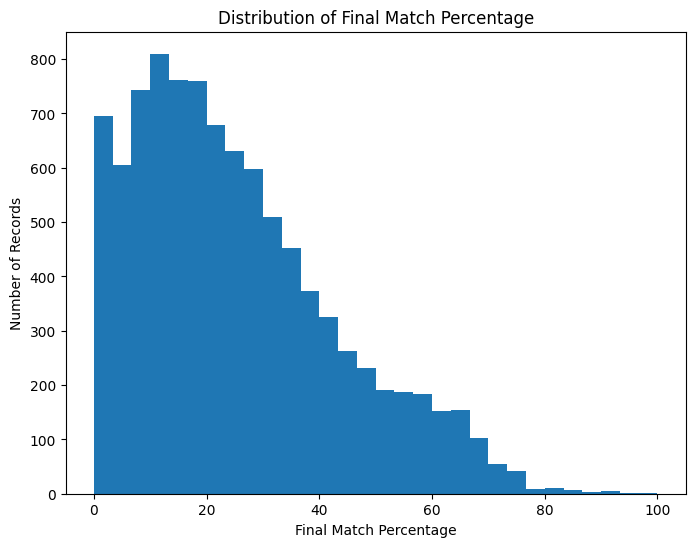

In [34]:
plt.figure(figsize=(8, 6))

plt.hist(
    df["final_match_percentage"],
    bins=30
)

plt.xlabel("Final Match Percentage")
plt.ylabel("Number of Records")
plt.title("Distribution of Final Match Percentage")

plt.show()

## 04. TF-IDF Similarity Distribution

TF-IDF similarity measures the similarity between the candidate text
and the job text using TF-IDF representations.

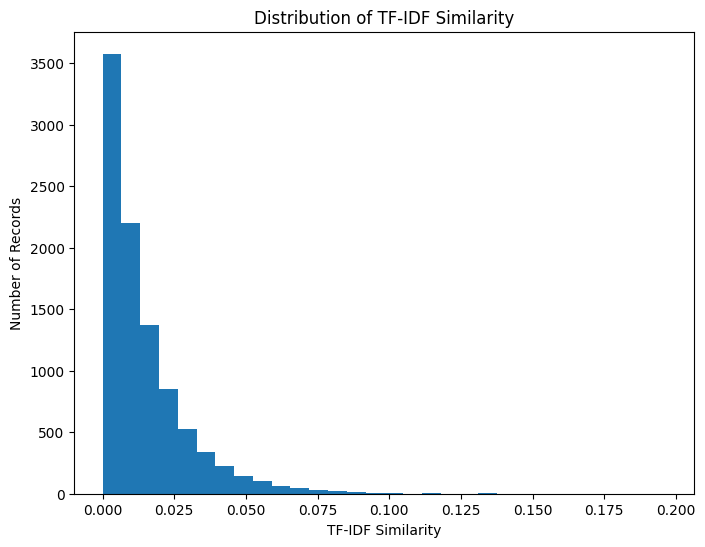

In [35]:
plt.figure(figsize=(8, 6))

plt.hist(
    df["tfidf_similarity"],
    bins=30
)

plt.xlabel("TF-IDF Similarity")
plt.ylabel("Number of Records")
plt.title("Distribution of TF-IDF Similarity")

plt.show()

## 05. Word2Vec Similarity Distribution

Word2Vec similarity provides a semantic similarity measure between
candidate and job text.

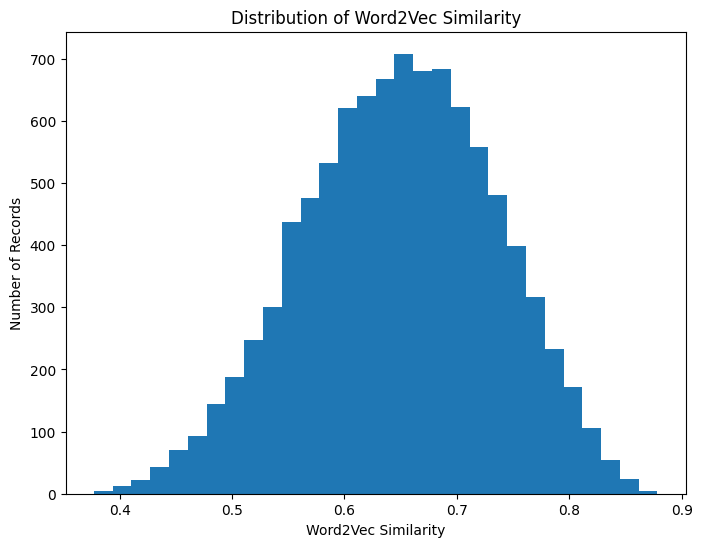

In [36]:
plt.figure(figsize=(8, 6))

plt.hist(
    df["word2vec_similarity"],
    bins=30
)

plt.xlabel("Word2Vec Similarity")
plt.ylabel("Number of Records")
plt.title("Distribution of Word2Vec Similarity")

plt.show()

## 06. Skill Coverage Distribution

Skill coverage measures how many required skills are matched by the
candidate skills.

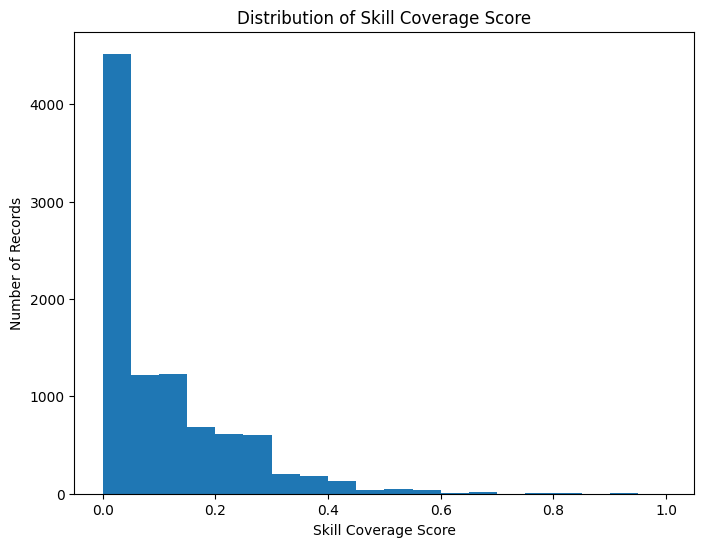

In [37]:
plt.figure(figsize=(8, 6))

plt.hist(
    df["skill_coverage_score"].dropna(),
    bins=20
)

plt.xlabel("Skill Coverage Score")
plt.ylabel("Number of Records")
plt.title("Distribution of Skill Coverage Score")

plt.show()

## 07. Correlation Analysis

We examine the relationship between the different matching signals.

In [38]:
correlation_columns=[
    "tfidf_similarity",
    "word2vec_similarity",
    "skill_coverage_score",
    "final_match_percentage"
]

df[correlation_columns].corr()

,tfidf_similarity,word2vec_similarity,skill_coverage_score,final_match_percentage
tfidf_similarity,1.000000,0.688113,0.694311,0.879458
word2vec_similarity,0.688113,1.000000,0.569874,0.873253
skill_coverage_score,0.694311,0.569874,1.000000,0.847965
final_match_percentage,0.879458,0.873253,0.847965,1.000000


## 08. Ranking Evaluation

The ranking quality is evaluated using Precision@5, Recall@5, and NDCG@5.

The reference threshold is 0.70 on `matched_score`, consistent with the match-quality threshold used in the classification stage.

The final matching method is compared with the TF-IDF baseline and the Word2Vec ranking signal.

In [39]:
REFERENCE_THRESHOLD = 0.70
K = 5

def ranking_metrics(group, score_column, k=5, threshold=0.70):
    group = group.dropna(subset=[score_column, "matched_score"])
    if group.empty:
        return np.nan, np.nan, np.nan
    ranked = group.sort_values(score_column, ascending=False)
    top_k = ranked.head(k)
    relevant = group["matched_score"] >= threshold
    relevant_top_k = top_k["matched_score"] >= threshold
    precision = relevant_top_k.mean()
    total_relevant = relevant.sum()
    recall = relevant_top_k.sum() / total_relevant if total_relevant > 0 else np.nan
    gains = relevant_top_k.astype(int).to_numpy()
    discounts = 1 / np.log2(np.arange(2, len(gains) + 2))
    dcg = np.sum(gains * discounts)
    ideal_gains = np.sort(relevant.astype(int).to_numpy())[::-1][:k]
    ideal_discounts = discounts[:len(ideal_gains)]
    idcg = np.sum(ideal_gains * ideal_discounts)
    ndcg = dcg / idcg if idcg > 0 else np.nan
    return precision, recall, ndcg

ranking_columns = {
    "TF-IDF Baseline": "tfidf_similarity",
    "Word2Vec": "word2vec_similarity",
    "Final Matching": "final_match_percentage"
}

ranking_results = []
for model_name, score_column in ranking_columns.items():
    values = []
    for _, group in df.groupby("job_position_name"):
        values.append(ranking_metrics(group, score_column, K, REFERENCE_THRESHOLD))
    values = np.array(values, dtype=float)
    ranking_results.append({
        "Model": model_name,
        "Precision@5": np.nanmean(values[:, 0]),
        "Recall@5": np.nanmean(values[:, 1]),
        "NDCG@5": np.nanmean(values[:, 2])
    })

ranking_results_df = pd.DataFrame(ranking_results)
ranking_results_df

,Model,Precision@5,Recall@5,NDCG@5
0,TF-IDF Baseline,0.814286,0.030675,0.823861
1,Word2Vec,0.864286,0.034745,0.862138
2,Final Matching,0.857143,0.033479,0.861161


In [40]:
ranking_results_path = Path("../Data/ranking_evaluation_results.csv")
ranking_results_df.to_csv(ranking_results_path, index=False)
print("Saved:", ranking_results_path)

Saved: ..\Data\ranking_evaluation_results.csv


## 08. TF-IDF Similarity vs Final Match

This visualization shows how TF-IDF similarity relates to the final
matching percentage.

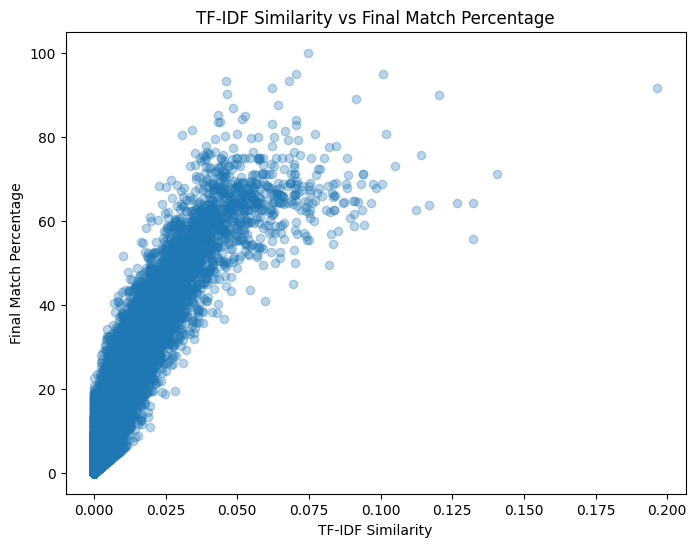

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["tfidf_similarity"],
    df["final_match_percentage"],
    alpha=0.3
)

plt.xlabel("TF-IDF Similarity")
plt.ylabel("Final Match Percentage")
plt.title("TF-IDF Similarity vs Final Match Percentage")

plt.show()

## 09. Word2Vec Similarity vs Final Match

This visualization shows how semantic similarity relates to the final
matching percentage.


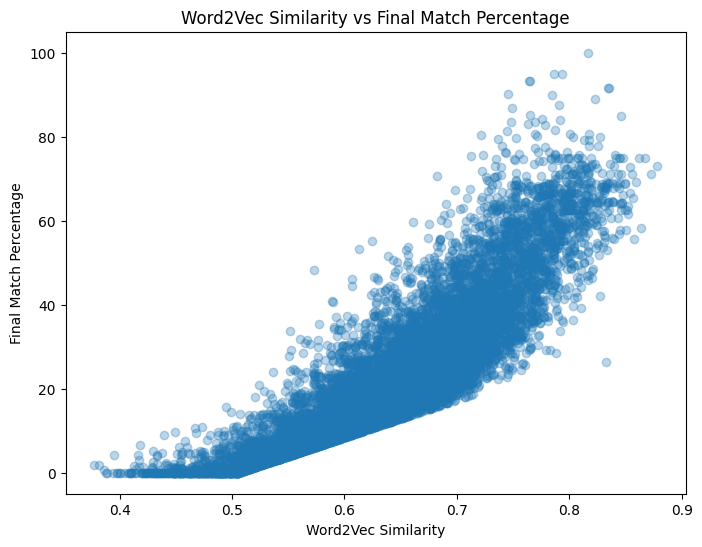

In [42]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["word2vec_similarity"],
    df["final_match_percentage"],
    alpha=0.3
)

plt.xlabel("Word2Vec Similarity")
plt.ylabel("Final Match Percentage")
plt.title("Word2Vec Similarity vs Final Match Percentage")

plt.show()

## 10. Skill Coverage vs Final Match

This visualization shows the relationship between skill coverage
and the final matching percentage.

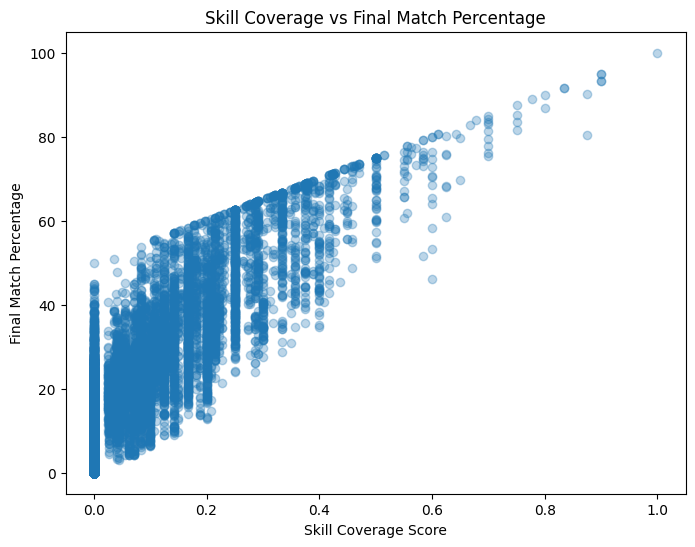

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["skill_coverage_score"],
    df["final_match_percentage"],
    alpha=0.3
)

plt.xlabel("Skill Coverage Score")
plt.ylabel("Final Match Percentage")
plt.title("Skill Coverage vs Final Match Percentage")

plt.show()

## 11. Top Matching Results

The following records have the highest final matching percentages.

In [44]:
top_matches=df.sort_values(
    "final_match_percentage",
    ascending=False
)

top_matches[
    [
        "job_position_name",
        "tfidf_similarity",
        "word2vec_similarity",
        "skill_coverage_score",
        "final_match_percentage"
    ]
].head(20)

,job_position_name,tfidf_similarity,word2vec_similarity,skill_coverage_score,final_match_percentage
8680,executive/ sr. executive -it,0.074758,0.816854,1.000000,100.000000
1559,mechanical engineer,0.070694,0.786367,0.900000,95.000000
5694,mechanical engineer,0.100783,0.793787,0.900000,95.000000
8809,mechanical engineer,0.046054,0.764948,0.900000,93.248591
5857,mechanical engineer,0.068182,0.764354,0.900000,93.195375
5112,executive/ sr. executive -it,0.196617,0.834917,0.833333,91.666667
2447,executive/ sr. executive -it,0.062026,0.834690,0.833333,91.666667
3116,senior software engineer,0.046436,0.745629,0.875000,90.269566
6676,mechanical engineer,0.120336,0.784283,0.800000,89.978982
1775,mechanical designer,0.091513,0.822723,0.777778,88.888889


## 12. Lowest Matching Results

The following records have the lowest final matching percentages.

In [45]:
lowest_matches = df.sort_values(
    "final_match_percentage",
    ascending=True
)

lowest_matches[
    [
        "job_position_name",
        "tfidf_similarity",
        "word2vec_similarity",
        "skill_coverage_score",
        "final_match_percentage"
    ]
].head(20)

,job_position_name,tfidf_similarity,word2vec_similarity,skill_coverage_score,final_match_percentage
1585,"executive/ senior executive- trade marketing, ...",0.0,0.478327,0.0,0.0
418,asst. manager/ manger (administrative),0.0,0.488364,0.0,0.0
406,head of internal control & compliance (icc) - ...,0.0,0.469184,0.0,0.0
3978,sr.officer / executive - internal audit,0.0,0.497611,0.0,0.0
2696,mechanical engineer,0.0,0.490275,0.0,0.0
2701,manager- human resource management (hrm),0.0,0.410123,0.0,0.0
1881,manager- human resource management (hrm),0.0,0.484461,0.0,0.0
3149,head of internal control & compliance (icc) - ...,0.0,0.449222,0.0,0.0
1896,executive - vat,0.0,0.476089,0.0,0.0
5169,executive - vat,0.0,0.462442,0.0,0.0


## 13. Skill Coverage Analysis

We examine records where skill coverage is available.

In [46]:
skill_coverage_data=df[
    df["skill_coverage_score"].notna()
    ]

print("Rows with skill coverage:",len(skill_coverage_data))
print("Rows without skill coverage:",
      df["skill_coverage_score"].isna().sum()
)

Rows with skill coverage: 9544
Rows without skill coverage: 0


In [47]:
skill_coverage_data[
    [
        "job_position_name",
        "skill_coverage_score",
        "final_match_percentage"
    ]
].sort_values(
    "skill_coverage_score",ascending=False
).head(20)

,job_position_name,skill_coverage_score,final_match_percentage
8680,executive/ sr. executive -it,1.000000,100.000000
8809,mechanical engineer,0.900000,93.248591
5694,mechanical engineer,0.900000,95.000000
5857,mechanical engineer,0.900000,93.195375
1559,mechanical engineer,0.900000,95.000000
9106,senior software engineer,0.875000,80.444138
3116,senior software engineer,0.875000,90.269566
5112,executive/ sr. executive -it,0.833333,91.666667
2447,executive/ sr. executive -it,0.833333,91.666667
6676,mechanical engineer,0.800000,89.978982


## 14. Difficult Matching Cases

Difficult cases are records where the text similarity and skill
coverage provide different levels of matching information.

These cases can help identify situations where the matching system
should be examined more carefully.

In [48]:
difficult_cases = df[
    (df["word2vec_similarity"] >= 0.75) &
    (
        df["skill_coverage_score"].fillna(0) == 0
    )
]

print("Number of difficult cases:", len(difficult_cases))

difficult_cases[
    [
        "job_position_name",
        "tfidf_similarity",
        "word2vec_similarity",
        "skill_coverage_score",
        "final_match_percentage"
    ]
].head(20)

Number of difficult cases: 38


,job_position_name,tfidf_similarity,word2vec_similarity,skill_coverage_score,final_match_percentage
148,executive/ sr. executive -it,0.031483,0.756294,0.0,40.140273
620,ai engineer,0.025717,0.773482,0.0,38.442955
1134,executive/ sr. executive -it,0.020302,0.803634,0.0,36.392184
1332,civil engineer,0.019993,0.753938,0.0,33.481840
1365,senior software engineer,0.011951,0.764721,0.0,29.934498
1562,executive/ sr. executive -it,0.022922,0.772704,0.0,36.804933
1907,data science engineer,0.026285,0.766225,0.0,38.112483
2391,manager- human resource management (hrm),0.009923,0.761099,0.0,28.472420
2510,site engineer,0.006446,0.787738,0.0,28.616976
2855,executive/ sr. executive -it,0.020535,0.751572,0.0,33.574658


## 15. Missing Skills Analysis

We examine the missing skills information from the skill matching
stage.

In [49]:
print(
    "Rows with skill coverage information:",
    df["skill_coverage_score"].notna().sum()
)

print(
    "Rows with missing-skill information:",
    df["missing_skills"].notna().sum()
)

df[
    [
        "job_position_name",
        "matched_skills",
        "missing_skills",
        "skill_coverage_percentage"
    ]
].head(20)

Rows with skill coverage information: 9544
Rows with missing-skill information: 9544


,job_position_name,matched_skills,missing_skills,skill_coverage_percentage
0,senior software engineer,[],"['documentation', 'software engineer', 'techni...",0.000000
1,machine learning (ml) engineer,"['data analysis', 'machine learning', 'machine...","['application development', 'functional', 'lea...",37.878788
2,"executive/ senior executive- trade marketing, ...",[],"['business administration', 'excel', 'marketin...",0.000000
3,business development executive,['fast'],"['business development', 'quality', 'reliable'...",20.000000
4,senior ios engineer,[],"['api', 'application development', 'integratio...",0.000000
5,ai engineer,['analytical skills (partial)'],"['artificial intelligence', 'data analysis', '...",3.571429
6,senior ios engineer,['requirement analysis (partial)'],"['api', 'application development', 'integratio...",5.555556
7,senior ios engineer,['ui design (partial)'],"['api', 'application development', 'integratio...",5.555556
8,mechanical engineer,[],"['machinery', 'maintenance', 'mechanical', 'me...",0.000000
9,business development executive,['business development (partial)'],"['fast', 'quality', 'reliable', 'typing']",10.000000


## 17. Reference-Based Error Analysis

We compare the final matching score with the dataset reference score using the same 0.70 match-quality threshold.

These cases are reported as potential false positives and false negatives relative to the reference threshold. They are used for analysis and should not be interpreted as definitive hiring errors.

In [50]:
REFERENCE_THRESHOLD = 0.70

df["predicted_good_match"] = df["final_match_percentage"] >= REFERENCE_THRESHOLD * 100
df["reference_good_match"] = df["matched_score"] >= REFERENCE_THRESHOLD

false_positive_cases = df[(df["predicted_good_match"] == True) & (df["reference_good_match"] == False)].copy()
false_negative_cases = df[(df["predicted_good_match"] == False) & (df["reference_good_match"] == True)].copy()

print("Potential false positives:", len(false_positive_cases))
print("Potential false negatives:", len(false_negative_cases))

error_columns = [
    "candidate_record_id", "job_position_name", "matched_score",
    "final_match_percentage", "tfidf_similarity", "word2vec_similarity",
    "skill_coverage_score", "matched_skills", "missing_skills"
]

false_positive_cases[error_columns].sort_values("final_match_percentage", ascending=False).head(10)

Potential false positives: 17
Potential false negatives: 4352


,candidate_record_id,job_position_name,matched_score,final_match_percentage,tfidf_similarity,word2vec_similarity,skill_coverage_score,matched_skills,missing_skills
3116,3117,senior software engineer,0.650000,90.269566,0.046436,0.745629,0.875000,"['documentation', 'software engineer (partial)...",[]
5206,5207,data science engineer,0.650000,83.928571,0.070497,0.791369,0.678571,"['api design (partial)', 'application developm...","['innovation', 'rest']"
9106,9107,senior software engineer,0.350000,80.444138,0.030833,0.721862,0.875000,"['documentation', 'software engineer (partial)...",[]
1840,1841,business development executive,0.350000,80.000000,0.057145,0.803255,0.600000,"['fast', 'quality', 'reliable']","['business development', 'typing']"
2562,2563,marketing officer,0.683333,79.166667,0.067624,0.813125,0.583333,"['functional', 'market', 'marketing', 'marketi...","['analytics', 'optimization']"
3017,3018,mechanical designer,0.683333,77.777778,0.062013,0.817171,0.555556,"['cad', 'mechanical', 'mechanical engineering'...","['autocad', 'documentation', 'drawings', 'manu..."
1284,1285,"executive/ senior executive- trade marketing, ...",0.576667,75.804018,0.040416,0.787149,0.562500,"['business administration (partial)', 'excel',...","['merchandising', 'promotion', 'supervision']"
8138,8139,site engineer,0.683333,73.076923,0.063020,0.818981,0.461538,"['autocad', 'cost control (partial)', 'invento...","['civil engineering', 'estimation', 'internet'..."
2326,2327,data engineer,0.650000,72.916667,0.105111,0.839744,0.458333,"['big data (partial)', 'data analytics', 'data...","['azure', 'etl', 'optimization', 'processes', ..."
241,242,senior software engineer,0.650000,72.714818,0.040480,0.784550,0.500000,"['technical support', 'troubleshooting']","['documentation', 'software engineer']"


In [51]:
false_negative_cases[error_columns].sort_values("matched_score", ascending=False).head(10)

,candidate_record_id,job_position_name,matched_score,final_match_percentage,tfidf_similarity,word2vec_similarity,skill_coverage_score,matched_skills,missing_skills
341,342,asst. manager/ manger (administrative),0.950000,29.901233,0.012217,0.716125,0.083333,"['administrative support (partial)', 'inventor...","['act', 'administrative', 'documentation', 'eq..."
966,967,asst. manager/ manger (administrative),0.950000,47.183448,0.020568,0.717201,0.333333,"['documentation', 'equipment maintenance', 'fi...","['act', 'administrative', 'administrative supp..."
6514,6515,manager- human resource management (hrm),0.950000,26.898671,0.009184,0.708246,0.071429,['database management (partial)'],"['business administration', 'coordination', 'd..."
749,750,management trainee - mechanical,0.950000,52.765039,0.027772,0.734399,0.333333,"['communication skills', 'mechanical engineeri...","['administrative support', 'maintenance', 'mec..."
8526,8527,asst. manager/ manger (administrative),0.950000,18.608559,0.010103,0.649756,0.000000,[],"['act', 'administrative', 'administrative supp..."
5630,5631,"full stack developer (python,react js)",0.950000,10.425406,0.004798,0.591584,0.000000,[],"['api design', 'aws', 'backend', 'database man..."
292,293,"full stack developer (python,react js)",0.950000,28.577730,0.008672,0.692525,0.138889,"['aws', 'python', 'python django (partial)']","['api design', 'backend', 'database management..."
4655,4656,system administrator (operation & maintenance ...,0.943333,8.929024,0.000715,0.600459,0.000000,[],"['account management', 'backup', 'cisco', 'cla..."
4280,4281,"full stack developer (python,react js)",0.940000,18.684609,0.007456,0.620644,0.083333,"['python', 'python django (partial)']","['api design', 'aws', 'backend', 'database man..."
5617,5618,"full stack developer (python,react js)",0.940000,69.444444,0.045551,0.796955,0.388889,"['django', 'git', 'javascript', 'postgresql', ...","['api design', 'aws', 'backend', 'database man..."


In [52]:
false_positive_export = false_positive_cases[error_columns].copy()
false_positive_export.insert(0, "error_type", "potential_false_positive")
false_negative_export = false_negative_cases[error_columns].copy()
false_negative_export.insert(0, "error_type", "potential_false_negative")
error_analysis_df = pd.concat([false_positive_export, false_negative_export], ignore_index=True)
error_analysis_path = Path("../Data/evaluation_error_analysis.csv")
error_analysis_df.to_csv(error_analysis_path, index=False)
print("Saved:", error_analysis_path)

Saved: ..\Data\evaluation_error_analysis.csv


## 18. Final Evaluation Summary

The following values summarize the final matching system results.

In [53]:
print("========== FINAL EVALUATION SUMMARY ==========")

print("Total rows:", len(df))
print("Average final match percentage:", df["final_match_percentage"].mean())
print("Minimum final match percentage:", df["final_match_percentage"].min())
print("Maximum final match percentage:", df["final_match_percentage"].max())
print("Average TF-IDF similarity:", df["tfidf_similarity"].mean())
print("Average Word2Vec similarity:", df["word2vec_similarity"].mean())
print("Average skill coverage:", df["skill_coverage_score"].mean())
print("\nRanking evaluation:")
print(ranking_results_df.to_string(index=False))


========== FINAL EVALUATION SUMMARY ==========
Total rows: 9544
Average final match percentage: 25.412741086536386
Minimum final match percentage: 0.0
Maximum final match percentage: 100.0
Average TF-IDF similarity: 0.014330514504449322
Average Word2Vec similarity: 0.6482397605574183
Average skill coverage: 0.09955883765345205

Ranking evaluation:
          Model  Precision@5  Recall@5   NDCG@5
TF-IDF Baseline     0.814286  0.030675 0.823861
       Word2Vec     0.864286  0.034745 0.862138
 Final Matching     0.857143  0.033479 0.861161


## 19. Final Evaluation Check

This final check verifies that the matching results are valid and that the final scores are within the expected range.

In [54]:
print("========== FINAL EVALUATION CHECK ==========")

print("Total rows:", len(df))
print("Missing final scores:", df["final_match_percentage"].isna().sum())
print("Scores below 0:", (df["final_match_percentage"] < 0).sum())
print("Scores above 100:", (df["final_match_percentage"] > 100).sum())
print("Missing reference scores:", df["matched_score"].isna().sum())
print("Reference scores below 0:", (df["matched_score"] < 0).sum())
print("Reference scores above 1:", (df["matched_score"] > 1).sum())
print("Rows with skill coverage:", df["skill_coverage_score"].notna().sum())


========== FINAL EVALUATION CHECK ==========
Total rows: 9544
Missing final scores: 0
Scores below 0: 0
Scores above 100: 0
Missing reference scores: 0
Reference scores below 0: 0
Reference scores above 1: 0
Rows with skill coverage: 9544


# Conclusion

The evaluation stage examined the final CV-job matching results using
text similarity, semantic similarity, skill coverage, score
distributions, correlations, top matches, low matches, and difficult
matching cases.

The results from this notebook will be used in the next stages of the
project for model evaluation, ranking analysis, and the final
application.